In [19]:
import pandas as pd
import numpy as np
import pandas_datareader as pdr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [20]:
date_range = {"start":'1989-10-01', "end":'2023-12-31', "freq": 'M'}
pcepilfe = pdr.get_data_fred('PCEPILFE', **date_range)  # chain index of PCE instead of nominal
dff = pdr.get_data_fred('DFF', **date_range)  # federal funds rate
unrate = pdr.get_data_fred('UNRATE', **date_range)  # unemployment rate
nrou = pdr.get_data_fred('NROU', **date_range).resample("MS").bfill()  # natural unemployment

In [21]:
unat = pd.Series(nrou["NROU"].values, index=nrou.index)
unat = unat.dropna()

u = pd.Series(unrate["UNRATE"].values, index=unrate.index).loc[unat.index]
pce = pd.Series(pcepilfe["PCEPILFE"].values, index=pcepilfe.index).loc[unat.index]
fedrate = pd.Series(dff["DFF"].values, index=dff.index).loc[unat.index]

In [22]:
r_star = 1
pi_star = 2

In [23]:
# output gap approximation from Okun's law
ogap = -2.0 * (u-unat)
infl = (np.log(pce).diff() * 100 * 12).dropna()  # annualized monthly inflation

taylor = (r_star + pi_star + 0.5 * (infl-pi_star) + 0.5 * ogap).dropna()

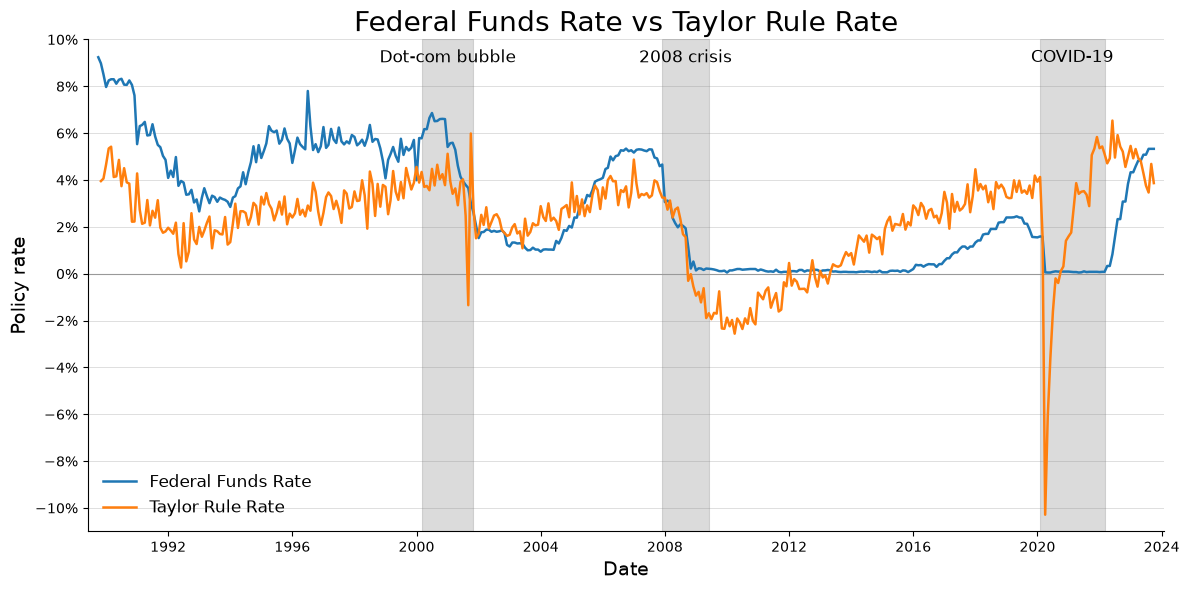

In [ ]:
EPISODES = {
    "Dot-com bubble": ("2000-03-01", "2001-11-01"),
    "2008 crisis": ("2007-12-01", "2009-06-01"),
    "COVID-19": ("2020-02-01", "2022-03-01"),
}

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_axisbelow(True)
ax.grid(axis="y", color="0.85", lw=0.6)
ax.axhline(0, color="0.6", lw=0.8)

for name, (start, end) in EPISODES.items():
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(start, end, facecolor="0.5", edgecolor="0.5", alpha=0.28, lw=0.8)
    ax.annotate(
        name,
        xy=(start + (end - start) / 2, 0.98),
        xycoords=("data", "axes fraction"),
        ha="center",
        va="top",
        fontsize=12,
    )

ax.plot(fedrate, lw=1.8, label="Federal Funds Rate")
ax.plot(taylor, lw=1.8, label="Taylor Rule Rate")

ax.set_title("Federal Funds Rate vs Taylor Rule Rate", fontsize=20)
ax.set_xlabel("Date", fontsize=14)
ax.set_ylabel("Policy rate", fontsize=14)
ax.set_ylim(-11, 10)
ax.yaxis.set_major_locator(mticker.MultipleLocator(2))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax.margins(x=0.01)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=12)

fig.tight_layout()
plt.show()